In [1]:
import pandas as pd
import pm4py

df = pd.read_csv("../data/BPI Challenge 2017.csv")
df["time:timestamp"] = pd.to_datetime(df["time:timestamp"], format="mixed")
print(df.shape)
df.head()



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




(1202267, 19)


,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,case:RequestedAmount,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID
0,Created,User_1,A_Create Application,Application,Application_652823628,complete,2016-01-01 09:51:15.304,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,statechange,User_1,A_Submitted,Application,ApplState_1582051990,complete,2016-01-01 09:51:15.352,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Created,User_1,W_Handle leads,Workflow,Workitem_1298499574,schedule,2016-01-01 09:51:15.774,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Deleted,User_1,W_Handle leads,Workflow,Workitem_1673366067,withdraw,2016-01-01 09:52:36.392,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Created,User_1,W_Complete application,Workflow,Workitem_1493664571,schedule,2016-01-01 09:52:36.403,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
n_cases = df["case:concept:name"].nunique()
n_events = len(df)
n_activities = df["concept:name"].nunique()
n_resources = df["org:resource"].nunique()

print("Cases:     ", n_cases)
print("Events:    ", n_events)
print("Activities:", n_activities)
print("Resources: ", n_resources)

Cases:      31509
Events:     1202267
Activities: 26
Resources:  149


In [3]:
print(df["EventOrigin"].value_counts())
print()
print(df["lifecycle:transition"].value_counts())

EventOrigin
Workflow       768823
Application    239595
Offer          193849
Name: count, dtype: int64

lifecycle:transition
complete     475306
suspend      215402
schedule     149104
start        128227
resume       127160
ate_abort     85224
withdraw      21844
Name: count, dtype: int64


In [4]:
# PM4Py mitteilen, welche Spalten Case, Activity und Zeit sind
df = pm4py.format_dataframe(df, case_id="case:concept:name",
                            activity_key="concept:name",
                            timestamp_key="time:timestamp")

# Varianten über alle Events
n_variants_all = len(pm4py.get_variants(df))

# Varianten nur über A_ und O_ Events
df_ao = df[df["EventOrigin"].isin(["Application", "Offer"])]
n_variants_ao = len(pm4py.get_variants(df_ao))

print("Varianten (alle Events): ", n_variants_all)
print("Varianten (nur A_ + O_): ", n_variants_ao)

Varianten (alle Events):  15930
Varianten (nur A_ + O_):  2630


In [5]:
case_times = df.groupby("case:concept:name")["time:timestamp"].agg(["min", "max"])
case_dur_days = (case_times["max"] - case_times["min"]).dt.total_seconds() / 86400

print("Falldauer in Tagen:")
print(case_dur_days.describe().round(1))

Falldauer in Tagen:
count    31509.0
mean        21.9
std         13.2
min          0.0
25%         11.3
50%         19.1
75%         31.5
max        286.1
dtype: float64


In [6]:
END_STATES = ["A_Pending", "A_Denied", "A_Cancelled"]

# letzten End-Zustand je Fall finden
ends = (df[df["concept:name"].isin(END_STATES)]
        .groupby("case:concept:name")["concept:name"].last())

outcome = pd.Series("Open", index=case_times.index)   # Standard: noch offen
outcome.loc[ends.index] = ends

print(outcome.value_counts())
print()
print((outcome.value_counts(normalize=True) * 100).round(1))

A_Pending      17228
A_Cancelled    10431
A_Denied        3752
Open              98
Name: count, dtype: int64

A_Pending      54.7
A_Cancelled    33.1
A_Denied       11.9
Open            0.3
Name: proportion, dtype: float64


In [7]:
cases = pd.DataFrame({"duration_days": case_dur_days, "outcome": outcome})
print(cases.groupby("outcome")["duration_days"].agg(["mean", "median"]).round(1))

             mean  median
outcome                  
A_Cancelled  29.9    31.6
A_Denied     16.8    14.1
A_Pending    18.1    14.8
Open         28.7    27.0


In [8]:
variants = pm4py.get_variants(df_ao)
top5 = sorted(variants.items(), key=lambda kv: -kv[1])[:5]

for variant, count in top5:
    print(f"{count} Fälle ({count / n_cases:.1%}):")
    print("   " + " -> ".join(variant))
    print()

5094 Fälle (16.2%):
   A_Create Application -> A_Submitted -> A_Concept -> A_Accepted -> O_Create Offer -> O_Created -> O_Sent (mail and online) -> A_Complete -> A_Cancelled -> O_Cancelled

1974 Fälle (6.3%):
   A_Create Application -> A_Submitted -> A_Concept -> A_Accepted -> O_Create Offer -> O_Created -> O_Sent (mail and online) -> A_Complete -> A_Validating -> O_Returned -> A_Incomplete -> A_Validating -> O_Accepted -> A_Pending

1913 Fälle (6.1%):
   A_Create Application -> A_Concept -> A_Accepted -> O_Create Offer -> O_Created -> O_Sent (mail and online) -> A_Complete -> A_Validating -> O_Returned -> O_Accepted -> A_Pending

1887 Fälle (6.0%):
   A_Create Application -> A_Concept -> A_Accepted -> O_Create Offer -> O_Created -> O_Sent (mail and online) -> A_Complete -> A_Cancelled -> O_Cancelled

1778 Fälle (5.6%):
   A_Create Application -> A_Submitted -> A_Concept -> A_Accepted -> O_Create Offer -> O_Created -> O_Sent (mail and online) -> A_Complete -> A_Validating -> O_Returned

In [9]:
q10 = cases["duration_days"].quantile(0.1)
q90 = cases["duration_days"].quantile(0.9)
short = cases[cases["duration_days"] <= q10]
long_ = cases[cases["duration_days"] >= q90]

print(f"Kurz = höchstens {q10:.1f} Tage, Lang = mindestens {q90:.1f} Tage\n")
print("Ergebnisse kurze Fälle:")
print(short["outcome"].value_counts(normalize=True).round(2))
print("\nErgebnisse lange Fälle:")
print(long_["outcome"].value_counts(normalize=True).round(2))

Kurz = höchstens 7.9 Tage, Lang = mindestens 35.1 Tage

Ergebnisse kurze Fälle:
outcome
A_Pending      0.56
A_Cancelled    0.30
A_Denied       0.14
Open           0.01
Name: proportion, dtype: float64

Ergebnisse lange Fälle:
outcome
A_Cancelled    0.50
A_Pending      0.43
A_Denied       0.06
Open           0.01
Name: proportion, dtype: float64


In [10]:
# Nur Workflow-Events mit relevanten Lifecycle-Übergängen
w = df[(df["EventOrigin"] == "Workflow") &
       df["lifecycle:transition"].isin(["start", "resume", "suspend", "complete", "ate_abort"])].copy()
w = w.sort_values(["case:concept:name", "concept:name", "time:timestamp"])

# Für jedes Event: Zeitpunkt und Typ des NÄCHSTEN Events derselben Activity im selben Fall
grp = w.groupby(["case:concept:name", "concept:name"])
w["next_ts"] = grp["time:timestamp"].shift(-1)
w["next_tr"] = grp["lifecycle:transition"].shift(-1)

# Ein Arbeitsabschnitt = start/resume, gefolgt von suspend/complete/ate_abort
seg = w[w["lifecycle:transition"].isin(["start", "resume"]) &
        w["next_tr"].isin(["suspend", "complete", "ate_abort"])]
seg_min = (seg["next_ts"] - seg["time:timestamp"]).dt.total_seconds() / 60

# Abschnitte pro Fall und Activity aufsummieren, dann Statistik je Activity
proc = seg_min.groupby([seg["case:concept:name"], seg["concept:name"]]).sum()
w_stats = proc.groupby(level=1).agg(["count", "mean", "std", "median"]).round(1)
w_stats.sort_values("count", ascending=False)

,count,mean,std,median
concept:name,,,,
W_Call after offers,31362,9.3,46.2,3.0
W_Complete application,29646,11.0,23.2,8.3
W_Validate application,21870,25.0,55.8,9.8
W_Call incomplete files,15003,15.7,43.8,7.9
W_Handle leads,3643,4.0,29.7,1.4
W_Assess potential fraud,301,144.2,290.4,16.0
W_Shortened completion,74,6.1,13.3,1.0
W_Personal Loan collection,2,2.5,0.9,2.5


In [11]:
# Fall-Attribute (pro Fall nur einmal nehmen)
case_attr = df.groupby("case:concept:name")[["case:LoanGoal", "case:ApplicationType",
                                             "case:RequestedAmount"]].first()
print(case_attr["case:LoanGoal"].value_counts(), "\n")
print(case_attr["case:ApplicationType"].value_counts(), "\n")
print(case_attr["case:RequestedAmount"].describe().round(0))

case:LoanGoal
Car                       9328
Home improvement          7669
Existing loan takeover    5601
Other, see explanation    2985
Unknown                   2365
Not speficied             1065
Remaining debt home        842
Extra spending limit       625
Caravan / Camper           369
Motorcycle                 275
Boat                       201
Tax payments               152
Business goal               30
Debt restructuring           2
Name: count, dtype: int64 

case:ApplicationType
New credit     28120
Limit raise     3389
Name: count, dtype: int64 

count     31509.0
mean      16234.0
std       15422.0
min           0.0
25%        6000.0
50%       12500.0
75%       21000.0
max      450000.0
Name: case:RequestedAmount, dtype: float64


In [12]:
# Angebots-Attribute: jedes Angebot hat genau ein "O_Create Offer"-Event
offers = df[df["concept:name"] == "O_Create Offer"]
print(offers[["OfferedAmount", "NumberOfTerms", "MonthlyCost", "CreditScore"]].describe().round(1))

# Wie viele Angebote bekommt ein Antrag?
offers_per_case = df.groupby("case:concept:name")["OfferID"].nunique()
print("\nAngebote pro Fall:")
print(offers_per_case.value_counts().sort_index())

       OfferedAmount  NumberOfTerms  MonthlyCost  CreditScore
count        42995.0        42995.0      42995.0      42995.0
mean         18513.7           83.0        281.4        318.6
std          13718.5           36.4        192.6        433.7
min           5000.0            5.0         43.0          0.0
25%           8800.0           56.0        152.8          0.0
50%          15000.0           77.0        244.5          0.0
75%          25000.0          120.0        350.0        848.0
max          75000.0          180.0       6673.8       1145.0

Angebote pro Fall:
OfferID
1     22950
2      6578
3      1348
4       443
5       126
6        30
7        16
8        13
9         3
10        2
Name: count, dtype: int64


In [13]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"A_Pending": "#2a9d8f", "A_Denied": "#e76f51",
          "A_Cancelled": "#8d99ae", "Open": "#cccccc"}

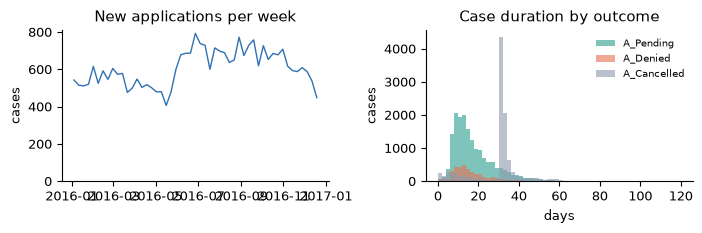

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.4))

# links: neue Anträge pro Woche (Startzeitpunkt jedes Falls)
weekly = case_times["min"].dt.tz_localize(None).dt.to_period("W").dt.start_time.value_counts().sort_index()
weekly = weekly.iloc[1:-1]                       # unvollständige erste/letzte Woche weglassen
ax[0].plot(weekly.index, weekly.values, lw=1, color="#3070b3")
ax[0].set(title="New applications per week", ylabel="cases", ylim=(0, None))

# rechts: Histogramm der Falldauer je Ergebnis
for o in ["A_Pending", "A_Denied", "A_Cancelled"]:
    ax[1].hist(cases.loc[cases["outcome"] == o, "duration_days"], bins=60, range=(0, 120),
               alpha=0.6, label=o, color=COLORS[o])
ax[1].set(title="Case duration by outcome", xlabel="days", ylabel="cases")
ax[1].legend(frameon=False, fontsize=7)

fig.tight_layout()
fig.savefig("../figures/fig_arrivals_duration.pdf", bbox_inches="tight")
plt.show()

In [15]:
import matplotlib.dates as mdates

In [16]:
ax[0].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

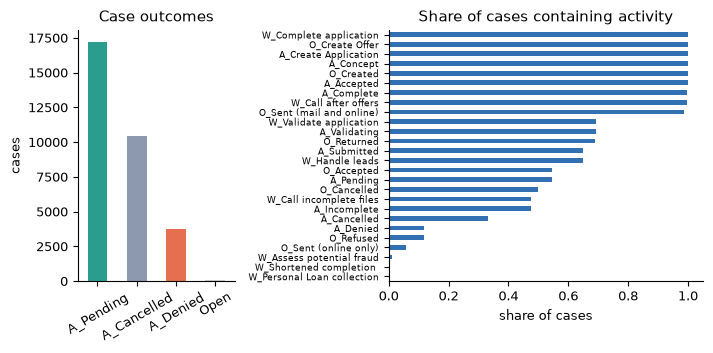

In [17]:
n_cases = df["case:concept:name"].nunique()
outcome_counts = cases["outcome"].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(7.2, 3.6), gridspec_kw={"width_ratios": [1, 2]})

# links: Anzahl Fälle je Ergebnis
outcome_counts.plot.bar(ax=ax[0], color=[COLORS[o] for o in outcome_counts.index])
ax[0].set(title="Case outcomes", ylabel="cases", xlabel="")
ax[0].tick_params(axis="x", rotation=30)

# rechts: In welchem Anteil der Fälle kommt jede Activity vor?
act_share = df.groupby("concept:name")["case:concept:name"].nunique().sort_values() / n_cases
act_share.plot.barh(ax=ax[1], color="#3070b3")
ax[1].set(title="Share of cases containing activity", xlabel="share of cases", ylabel="")
ax[1].tick_params(axis="y", labelsize=6.5)

fig.tight_layout()
fig.savefig("../figures/fig_outcomes_activities.pdf", bbox_inches="tight")
plt.show()

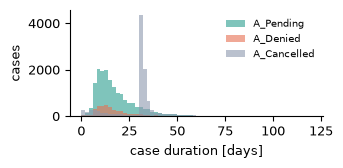

In [18]:
fig, ax = plt.subplots(figsize=(3.4, 1.75))
for o in ["A_Pending", "A_Denied", "A_Cancelled"]:
    ax.hist(cases.loc[cases["outcome"] == o, "duration_days"], bins=60, range=(0, 120),
            alpha=0.6, label=o, color=COLORS[o])
ax.set(xlabel="case duration [days]", ylabel="cases")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig("../figures/fig_duration_outcome.pdf", bbox_inches="tight")
plt.show()